In [1]:
import numpy as np
import pygad
import time
import matplotlib.pyplot as plt
from inventory_model import *

def decode(genes):
    """200 multipliers -> (50, 4) order plan"""
    m = np.clip(np.array(genes), 0, 1.5).reshape(N, W)
    return m * weekly_fc

def fitness_func(ga_instance, solution, solution_idx):
    return fitness(decode(solution))

baseline = BUDGET_FACTOR * weekly_fc

In [3]:
def on_generation(ga):
    g = ga.generations_completed
    if g % 25 == 0:
        print(f"Generation {g}: best fitness = {ga.best_solution()[1]:,.0f}")

ga = pygad.GA(
    num_generations=300,
    num_parents_mating=40,
    sol_per_pop=80,
    num_genes=N * W,
    fitness_func=fitness_func,
    init_range_low=0.0,
    init_range_high=1.5,
    gene_type=float,
    parent_selection_type="tournament",
    K_tournament=3,
    crossover_type="uniform",
    mutation_type="random",
    mutation_percent_genes=10,
    mutation_by_replacement=False,
    random_mutation_min_val=-0.1,
    random_mutation_max_val=0.1,
    keep_elitism=2,
    random_seed=42,
    on_generation=on_generation,
)

start = time.time()
ga.run()
print(f"Done in {(time.time() - start) / 60:.1f} minutes")

Generation 25: best fitness = 690,773
Generation 50: best fitness = 722,837
Generation 75: best fitness = 729,837
Generation 100: best fitness = 735,142
Generation 125: best fitness = 736,817
Generation 150: best fitness = 737,989
Generation 175: best fitness = 739,516
Generation 200: best fitness = 740,579
Generation 225: best fitness = 740,902
Generation 250: best fitness = 740,902
Generation 275: best fitness = 741,152
Generation 300: best fitness = 741,607
Done in 3.4 minutes


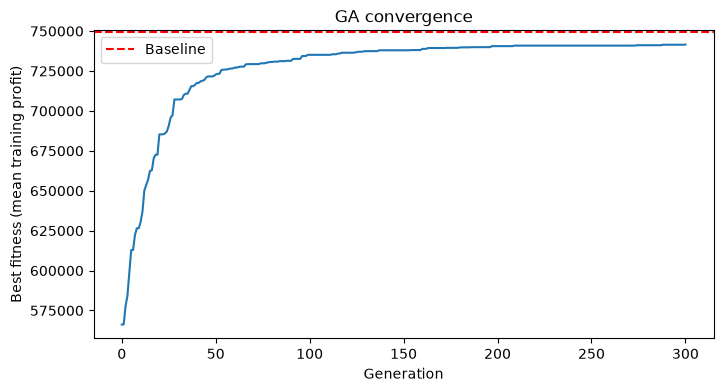

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(ga.best_solutions_fitness)
plt.axhline(fitness(baseline), color="red", linestyle="--", label="Baseline")
plt.xlabel("Generation")
plt.ylabel("Best fitness (mean training profit)")
plt.title("GA convergence")
plt.legend()
plt.show()

In [5]:
solution, best_fit, _ = ga.best_solution()
plan = decode(solution)

def report(name, p):
    v = simulate_profit(p, val_scen)
    a = simulate_profit(p, actual)[0]
    print(f"{name:9s} | validation mean {v.mean():>9,.0f} | 5th pct {np.percentile(v, 5):>9,.0f} "
          f"| real 2017 {a:>9,.0f} | spend {COST * p.sum():>9,.0f} | penalty {penalty(p):.0f}")

report("Baseline", baseline)
report("GA plan", plan)

gain = simulate_profit(plan, val_scen).mean() / simulate_profit(baseline, val_scen).mean() - 1
print(f"\nGA improvement on validation scenarios: {gain:.2%}")

Baseline  | validation mean   749,270 | 5th pct   746,321 | real 2017   751,888 | spend   978,523 | penalty 0
GA plan   | validation mean   741,682 | 5th pct   738,660 | real 2017   741,904 | spend   978,396 | penalty 0

GA improvement on validation scenarios: -1.01%


In [6]:
np.save("best_plan.npy", plan)
np.save("convergence.npy", np.array(ga.best_solutions_fitness))